## imports and files

In [1]:
import pandas as pd
import numpy as np
import os
from datetime import datetime
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_rows', 300)
pd.set_option('display.width', 160)

CITIES_WAVES = {
    'Bristol':    {'2025-09-26': 'data/Bristol_26September2025.csv',
                   '2026-06-29': 'data/Bristol_29June2026.csv'},
    'Edinburgh':  {'2025-09-21': 'data/Edinburgh_21September2025.csv',
                   '2026-06-23': 'data/Edinburgh_23June2026.csv'},
    'London':     {'2025-09-14': 'data/London_14 September2025.csv',
                   '2026-06-19': 'data/London_19June2026.csv'},
    'Manchester': {'2025-09-26': 'data/Manchester_26September2025.csv',
                   '2026-06-28': 'data/Manchester_28June2026.csv'},
}

TARGET_RAW = 'estimated_occupancy_l365d'
ID_COL     = 'id'
NEIGHBOURHOOD_COL_CANDIDATES = ['neighbourhood_cleansed', 'neighbourhood']

# --- File existence check: hard error if anything is missing ---
file_check_rows = []
missing_files = []

for city, waves in CITIES_WAVES.items():
    for wave_date, path in sorted(waves.items()):
        exists = os.path.exists(path)
        file_check_rows.append({'city': city, 'wave_date': wave_date, 'path': path,
                                 'status': 'FOUND' if exists else 'MISSING'})
        if not exists:
            missing_files.append(path)

file_check_df = pd.DataFrame(file_check_rows)
print('FILE EXISTENCE CHECK')
display(file_check_df)

if missing_files:
    raise FileNotFoundError(
        f"\n\nThe following {len(missing_files)} file(s) were not found:\n" +
        '\n'.join(f'  - {p}' for p in missing_files) +
        "\n\nFix the filenames/paths in CITIES_WAVES above and re-run."
    )
else:
    print(f'\nAll {len(file_check_df)} files found. Proceeding.')


FILE EXISTENCE CHECK


,city,wave_date,path,status
0,Bristol,2025-09-26,data/Bristol_26September2025.csv,FOUND
1,Bristol,2026-06-29,data/Bristol_29June2026.csv,FOUND
2,Edinburgh,2025-09-21,data/Edinburgh_21September2025.csv,FOUND
3,Edinburgh,2026-06-23,data/Edinburgh_23June2026.csv,FOUND
4,London,2025-09-14,data/London_14 September2025.csv,FOUND
5,London,2026-06-19,data/London_19June2026.csv,FOUND
6,Manchester,2025-09-26,data/Manchester_26September2025.csv,FOUND
7,Manchester,2026-06-28,data/Manchester_28June2026.csv,FOUND



All 8 files found. Proceeding.


In [10]:
df_b = pd.read_csv("data/Bristol_26September2025.csv")
cols = df_b.columns 
result = [i for i in cols if "oc" in i]
sum(df_b["estimated_occupancy_l365d"] == 0)

755

## raw data

In [2]:
raw_dfs = {}       # (city, wave_date) -> raw dataframe (loaded once, reused everywhere below)
shape_rows = []

for city, waves in CITIES_WAVES.items():
    for wave_date, path in sorted(waves.items()):
        raw = pd.read_csv(path, low_memory=False)
        raw_dfs[(city, wave_date)] = raw
        shape_rows.append({'city': city, 'wave_date': wave_date,
                            'rows': raw.shape[0], 'columns': raw.shape[1]})

shape_df = pd.DataFrame(shape_rows)
print('RAW SHAPE — every (city, wave)')
display(shape_df)

# --- Schema diff: wave 1 vs wave 2, per city ---
schema_rows = []
for city, waves in CITIES_WAVES.items():
    dates = sorted(waves.keys())
    d1, d2 = dates[0], dates[1]
    cols1 = set(raw_dfs[(city, d1)].columns)
    cols2 = set(raw_dfs[(city, d2)].columns)
    added, removed = sorted(cols2 - cols1), sorted(cols1 - cols2)
    schema_rows.append({
        'city': city, 'wave_1': d1, 'wave_2': d2,
        'cols_wave1': len(cols1), 'cols_wave2': len(cols2),
        'n_added': len(added), 'n_removed': len(removed),
        'added_columns': ', '.join(added) if added else '-',
        'removed_columns': ', '.join(removed) if removed else '-',
    })

schema_df = pd.DataFrame(schema_rows)
print('\nSCHEMA DIFF — wave 1 vs wave 2, per city')
display(schema_df[['city','wave_1','wave_2','cols_wave1','cols_wave2','n_added','n_removed']])
print('\nAdded columns detail (identical across all 4 cities if schema change was platform-wide):')
display(schema_df[['city','added_columns']])
print('\nRemoved columns detail:')
display(schema_df[['city','removed_columns']])


RAW SHAPE — every (city, wave)


,city,wave_date,rows,columns
0,Bristol,2025-09-26,2845,79
1,Bristol,2026-06-29,3023,90
2,Edinburgh,2025-09-21,4936,79
3,Edinburgh,2026-06-23,6244,90
4,London,2025-09-14,96871,79
5,London,2026-06-19,92638,90
6,Manchester,2025-09-26,7418,79
7,Manchester,2026-06-28,6930,90



SCHEMA DIFF — wave 1 vs wave 2, per city


,city,wave_1,wave_2,cols_wave1,cols_wave2,n_added,n_removed
0,Bristol,2025-09-26,2026-06-29,79,90,11,0
1,Edinburgh,2025-09-21,2026-06-23,79,90,11,0
2,London,2025-09-14,2026-06-19,79,90,11,0
3,Manchester,2025-09-26,2026-06-28,79,90,11,0



Added columns detail (identical across all 4 cities if schema change was platform-wide):


,city,added_columns
0,Bristol,"host_profile_id, host_profile_url, hosts_time_..."
1,Edinburgh,"host_profile_id, host_profile_url, hosts_time_..."
2,London,"host_profile_id, host_profile_url, hosts_time_..."
3,Manchester,"host_profile_id, host_profile_url, hosts_time_..."



Removed columns detail:


,city,removed_columns
0,Bristol,-
1,Edinburgh,-
2,London,-
3,Manchester,-


## Listing before cleaning

In [3]:
listing_rows = []

for city, waves in CITIES_WAVES.items():
    dates = sorted(waves.keys())
    d1, d2 = dates[0], dates[1]
    df1, df2 = raw_dfs[(city, d1)], raw_dfs[(city, d2)]

    n1, n2 = len(df1), len(df2)
    dup1 = n1 - df1[ID_COL].nunique()
    dup2 = n2 - df2[ID_COL].nunique()

    ids1 = set(df1[ID_COL])
    ids2 = set(df2[ID_COL])
    total_rows       = n1 + n2                  # simple sum (both waves combined)
    total_unique     = len(ids1 | ids2)          # union across waves = true unique listings

    # NOTE: column names are kept generic (wave1_*, wave2_*) rather than embedding the
    # actual date - dates differ per city, and f-string dates as column names would create
    # a different column per city, leaving every other city's cell NaN in the final table.
    # The actual dates are still recorded, just as their own columns.
    listing_rows.append({
        'city': city,
        'wave1_date': d1,
        'wave1_listings': n1,
        'wave1_duplicates': dup1,
        'wave2_date': d2,
        'wave2_listings': n2,
        'wave2_duplicates': dup2,
        'total_rows_both_waves': total_rows,
        'total_unique_listings': total_unique,
    })

listing_df = pd.DataFrame(listing_rows)
print('LISTING COUNTS — before cleaning')
display(listing_df)


LISTING COUNTS — before cleaning


,city,wave1_date,wave1_listings,wave1_duplicates,wave2_date,wave2_listings,wave2_duplicates,total_rows_both_waves,total_unique_listings
0,Bristol,2025-09-26,2845,0,2026-06-29,3023,0,5868,3594
1,Edinburgh,2025-09-21,4936,0,2026-06-23,6244,0,11180,7060
2,London,2025-09-14,96871,0,2026-06-19,92638,0,189509,119140
3,Manchester,2025-09-26,7418,0,2026-06-28,6930,0,14348,9785


## Cleaning

In [4]:
def fix_price(s):
    return pd.to_numeric(s.astype(str).str.replace(r'[$,]', '', regex=True), errors='coerce')

def get_neighbourhood_col(df):
    for c in NEIGHBOURHOOD_COL_CANDIDATES:
        if c in df.columns:
            return c
    return None


def clean_with_reasons(df):
    """Applies each cleaning rule and records exactly how many rows were
    removed BY THAT RULE (not cumulative overlap-hidden counts). Order:
      1. inactive        - occupancy==0 AND number_of_reviews==0
      2. occ_invalid     - occupancy negative/unparseable
      3. minnights_bad   - minimum_nights outside 1-365
      4. price_missing   - price is null/unparseable  (reported separately from true outliers)
      5. price_outlier   - price outside 5-10000 (excludes nulls, counted above)
    Returns the final cleaned df plus a dict of {reason: rows_removed}.
    """
    n0 = len(df)
    reasons = {}
    working = df.copy()

    occ = pd.to_numeric(working.get(TARGET_RAW, np.nan), errors='coerce')
    nr  = pd.to_numeric(working.get('number_of_reviews', pd.Series(1, index=working.index)), errors='coerce').fillna(0)
    inactive_mask = occ.fillna(0).eq(0) & nr.eq(0)
    reasons['inactive (0 occupancy & 0 reviews)'] = int(inactive_mask.sum())
    working = working[~inactive_mask]

    occ2 = pd.to_numeric(working[TARGET_RAW], errors='coerce')
    occ_invalid_mask = occ2.isna() | (occ2 < 0)
    reasons['occupancy invalid/negative'] = int(occ_invalid_mask.sum())
    working = working[~occ_invalid_mask]

    if 'minimum_nights' in working.columns:
        mn = pd.to_numeric(working['minimum_nights'], errors='coerce')
        mn_bad_mask = mn.isna() | (mn < 1) | (mn > 365)
        reasons['minimum_nights out of range (1-365)'] = int(mn_bad_mask.sum())
        working = working[~mn_bad_mask]
    else:
        reasons['minimum_nights out of range (1-365)'] = 0

    if 'price' in working.columns:
        price = fix_price(working['price'])
        price_missing_mask = price.isna()
        reasons['price missing (null)'] = int(price_missing_mask.sum())
        working = working[~price_missing_mask]

        price2 = fix_price(working['price'])
        price_outlier_mask = (price2 < 5) | (price2 > 10000)
        reasons['price outlier (outside 5-10000)'] = int(price_outlier_mask.sum())
        working = working[~price_outlier_mask]
    else:
        reasons['price missing (null)'] = 0
        reasons['price outlier (outside 5-10000)'] = 0

    reasons['TOTAL REMOVED'] = n0 - len(working)
    reasons['FINAL (retained)'] = len(working)
    reasons['n_raw'] = n0
    return working, reasons


clean_dfs = {}
cleaning_rows = []

for city, waves in CITIES_WAVES.items():
    for wave_date, path in sorted(waves.items()):
        raw = raw_dfs[(city, wave_date)]
        if raw[ID_COL].duplicated().any():
            raw = raw.drop_duplicates(subset=ID_COL, keep='first')
        clean, reasons = clean_with_reasons(raw)
        clean = clean.copy()
        clean['city'] = city
        clean['wave_date'] = wave_date
        clean['listing_id'] = clean[ID_COL]
        clean_dfs[(city, wave_date)] = clean

        row = {'city': city, 'wave_date': wave_date}
        row.update(reasons)
        cleaning_rows.append(row)

cleaning_df = pd.DataFrame(cleaning_rows)
reason_cols = ['inactive (0 occupancy & 0 reviews)', 'occupancy invalid/negative',
               'minimum_nights out of range (1-365)', 'price missing (null)',
               'price outlier (outside 5-10000)']

# --- table: counts removed by reason ---
print('CLEANING BREAKDOWN — rows removed, BY REASON (count)')
display(cleaning_df[['city','wave_date','n_raw'] + reason_cols + ['TOTAL REMOVED','FINAL (retained)']])

# --- table: same thing as % of raw rows for that (city, wave) ---
pct_df = cleaning_df[['city','wave_date']].copy()
for col in reason_cols + ['TOTAL REMOVED', 'FINAL (retained)']:
    pct_df[col] = (cleaning_df[col] / cleaning_df['n_raw'] * 100).round(1)
print('\nCLEANING BREAKDOWN — as % of raw rows for that wave')
display(pct_df)


CLEANING BREAKDOWN — rows removed, BY REASON (count)


,city,wave_date,n_raw,inactive (0 occupancy & 0 reviews),occupancy invalid/negative,minimum_nights out of range (1-365),price missing (null),price outlier (outside 5-10000),TOTAL REMOVED,FINAL (retained)
0,Bristol,2025-09-26,2845,322,0,0,555,2,879,1966
1,Bristol,2026-06-29,3023,374,0,2,525,1,902,2121
2,Edinburgh,2025-09-21,4936,286,0,0,5,17,308,4628
3,Edinburgh,2026-06-23,6244,661,0,2,551,3,1217,5027
4,London,2025-09-14,96871,24122,0,20,24679,18,48839,48032
5,London,2026-06-19,92638,21927,0,22,22022,14,43985,48653
6,Manchester,2025-09-26,7418,1351,0,3,697,1,2052,5366
7,Manchester,2026-06-28,6930,1359,0,1,77,0,1437,5493



CLEANING BREAKDOWN — as % of raw rows for that wave


,city,wave_date,inactive (0 occupancy & 0 reviews),occupancy invalid/negative,minimum_nights out of range (1-365),price missing (null),price outlier (outside 5-10000),TOTAL REMOVED,FINAL (retained)
0,Bristol,2025-09-26,11.3,0.0,0.0,19.5,0.1,30.9,69.1
1,Bristol,2026-06-29,12.4,0.0,0.1,17.4,0.0,29.8,70.2
2,Edinburgh,2025-09-21,5.8,0.0,0.0,0.1,0.3,6.2,93.8
3,Edinburgh,2026-06-23,10.6,0.0,0.0,8.8,0.0,19.5,80.5
4,London,2025-09-14,24.9,0.0,0.0,25.5,0.0,50.4,49.6
5,London,2026-06-19,23.7,0.0,0.0,23.8,0.0,47.5,52.5
6,Manchester,2025-09-26,18.2,0.0,0.0,9.4,0.0,27.7,72.3
7,Manchester,2026-06-28,19.6,0.0,0.0,1.1,0.0,20.7,79.3


### Reason of remove

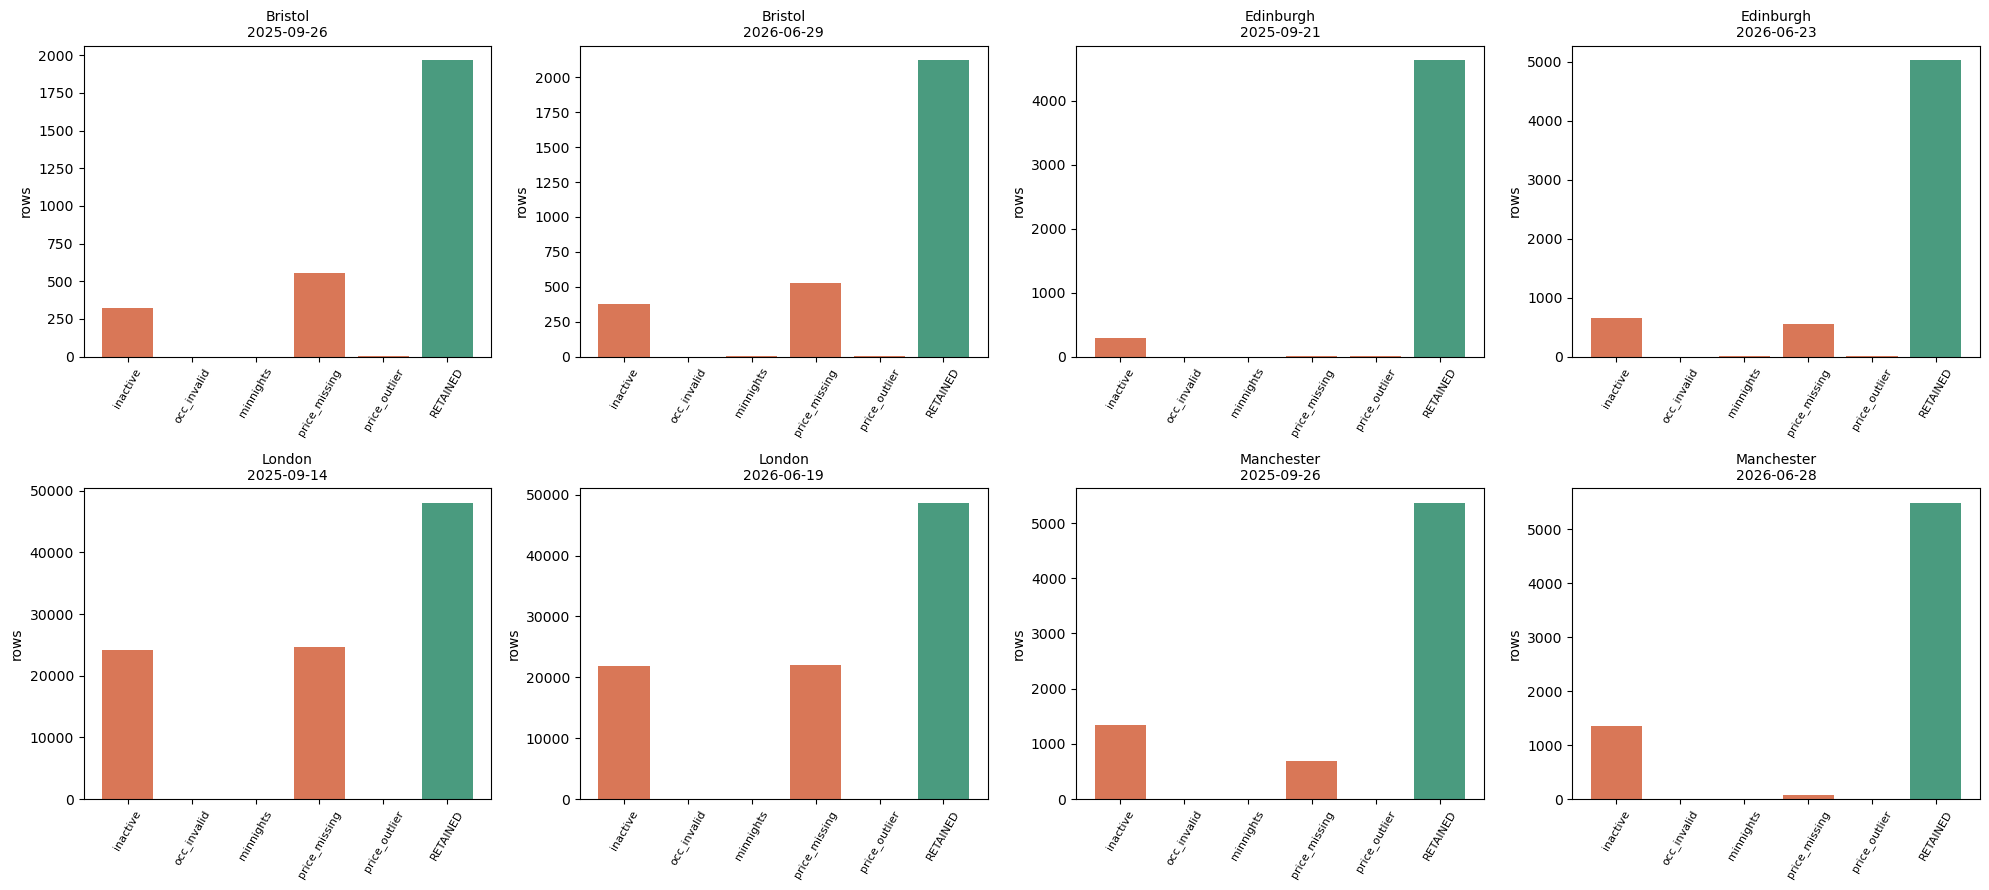

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharey=False)

for idx, ((city, wave_date), clean) in enumerate(clean_dfs.items()):
    row_data = cleaning_df[(cleaning_df.city == city) & (cleaning_df.wave_date == wave_date)].iloc[0]
    ax = axes.flat[idx]
    values = [row_data[c] for c in reason_cols]
    values.append(row_data['FINAL (retained)'])
    labels = ['inactive', 'occ_invalid', 'minnights', 'price_missing', 'price_outlier', 'RETAINED']
    colors = ['#d97757']*5 + ['#4a9b7f']
    ax.bar(labels, values, color=colors)
    ax.set_title(f'{city}\n{wave_date}', fontsize=10)
    ax.tick_params(axis='x', rotation=60, labelsize=8)
    ax.set_ylabel('rows')

plt.tight_layout()
plt.show()


## Listing after cleaning

In [6]:
listing_clean_rows = []

for city, waves in CITIES_WAVES.items():
    dates = sorted(waves.keys())
    d1, d2 = dates[0], dates[1]
    c1, c2 = clean_dfs[(city, d1)], clean_dfs[(city, d2)]

    n1, n2 = len(c1), len(c2)
    ids1, ids2 = set(c1['listing_id']), set(c2['listing_id'])
    both     = ids1 & ids2
    only1    = ids1 - ids2
    only2    = ids2 - ids1
    total_rows   = n1 + n2
    total_unique = len(ids1 | ids2)

    listing_clean_rows.append({
        'city': city,
        'wave1_date': d1,
        'wave1_clean': n1,
        'wave2_date': d2,
        'wave2_clean': n2,
        'total_rows_both_waves': total_rows,
        'total_unique_listings': total_unique,
        'in_both_waves': len(both),
        'only_wave1': len(only1),
        'only_wave2': len(only2),
        'pct_turnover': round((len(only1)+len(only2)) / total_unique * 100, 1),
    })

listing_clean_df = pd.DataFrame(listing_clean_rows)
print('LISTING COUNTS — after cleaning')
display(listing_clean_df)


LISTING COUNTS — after cleaning


,city,wave1_date,wave1_clean,wave2_date,wave2_clean,total_rows_both_waves,total_unique_listings,in_both_waves,only_wave1,only_wave2,pct_turnover
0,Bristol,2025-09-26,1966,2026-06-29,2121,4087,2637,1450,516,671,45.0
1,Edinburgh,2025-09-21,4628,2026-06-23,5027,9655,6056,3599,1029,1428,40.6
2,London,2025-09-14,48032,2026-06-19,48653,96685,66069,30616,17416,18037,53.7
3,Manchester,2025-09-26,5366,2026-06-28,5493,10859,7275,3584,1782,1909,50.7


## (Neighbourhood)

In [7]:
neighbourhood_summary_rows = []
neighbourhood_tables = {}

for city, waves in CITIES_WAVES.items():
    dates = sorted(waves.keys())
    combined = pd.concat([clean_dfs[(city, d)] for d in dates], ignore_index=True)
    nb_col = get_neighbourhood_col(combined)

    if nb_col is None:
        neighbourhood_summary_rows.append({'city': city, 'neighbourhood_col': 'NOT FOUND'})
        continue

    counts = combined[nb_col].value_counts(dropna=False)
    neighbourhood_tables[city] = counts

    neighbourhood_summary_rows.append({
        'city': city, 'neighbourhood_col': nb_col,
        'n_neighbourhoods': counts.shape[0],
        'min_listings': counts.min(), 'median_listings': counts.median(),
        'max_listings': counts.max(),
        'n_neighbourhoods_under_10': int((counts < 10).sum()),
    })

nb_summary_df = pd.DataFrame(neighbourhood_summary_rows)
print('NEIGHBOURHOOD SUMMARY — per city (post-cleaning, both waves combined)')
display(nb_summary_df)

print('\nTop 10 and bottom 10 neighbourhoods per city:')
for city, counts in neighbourhood_tables.items():
    print(f'\n[{city}]')
    display(pd.concat([counts.head(10).rename('n_listings (top 10)'),
                        counts.tail(10).rename('n_listings (bottom 10)')], axis=1))


NEIGHBOURHOOD SUMMARY — per city (post-cleaning, both waves combined)


,city,neighbourhood_col,n_neighbourhoods,min_listings,median_listings,max_listings,n_neighbourhoods_under_10
0,Bristol,neighbourhood_cleansed,34,17,84.5,431,0
1,Edinburgh,neighbourhood_cleansed,111,3,42.0,1257,6
2,London,neighbourhood_cleansed,33,526,1948.0,12986,0
3,Manchester,neighbourhood_cleansed,41,26,120.0,2063,0



Top 10 and bottom 10 neighbourhoods per city:

[Bristol]


,n_listings (top 10),n_listings (bottom 10)
neighbourhood_cleansed,,
Central,431.0,NaN
Ashley,424.0,NaN
Clifton Down,302.0,NaN
Clifton,271.0,NaN
Southville,212.0,NaN
Lawrence Hill,202.0,NaN
Cotham,193.0,NaN
Hotwells & Harbourside,172.0,NaN
Easton,156.0,NaN



[Edinburgh]


,n_listings (top 10),n_listings (bottom 10)
neighbourhood_cleansed,,
"Old Town, Princes Street and Leith Street",1257.0,NaN
Deans Village,616.0,NaN
Tollcross,512.0,NaN
New Town West,379.0,NaN
Hillside and Calton Hill,342.0,NaN
"Canongate, Southside and Dumbiedykes",310.0,NaN
New Town East and Gayfield,283.0,NaN
Meadows and Southside,250.0,NaN
Dalry and Fountainbridge,247.0,NaN



[London]


,n_listings (top 10),n_listings (bottom 10)
neighbourhood_cleansed,,
Westminster,12986.0,NaN
Camden,7306.0,NaN
Kensington and Chelsea,7211.0,NaN
Tower Hamlets,6606.0,NaN
Southwark,5079.0,NaN
Hackney,5041.0,NaN
Lambeth,4677.0,NaN
Wandsworth,4652.0,NaN
Islington,4550.0,NaN



[Manchester]


,n_listings (top 10),n_listings (bottom 10)
neighbourhood_cleansed,,
Salford District,2063.0,NaN
Trafford District,1082.0,NaN
Ancoats and Clayton,891.0,NaN
City Centre,774.0,NaN
Stockport District,671.0,NaN
Oldham District,432.0,NaN
Tameside District,394.0,NaN
Wigan District,378.0,NaN
Bradford,346.0,NaN


### Neighbourhoods

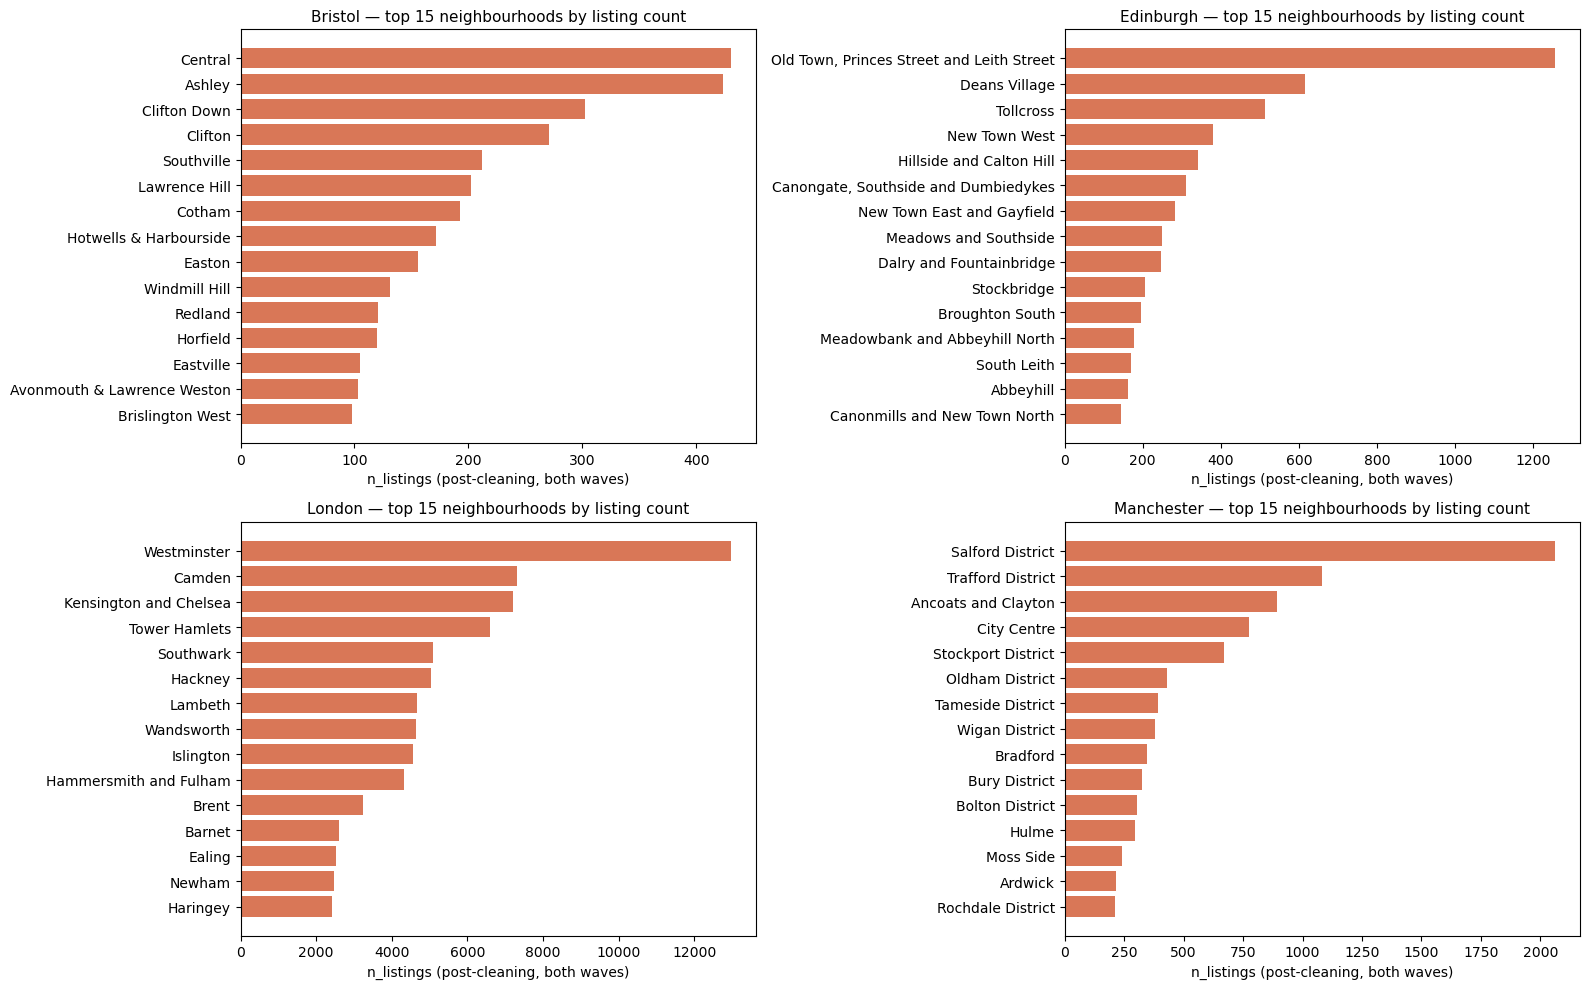

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, (city, counts) in zip(axes.flat, neighbourhood_tables.items()):
    top15 = counts.head(15)
    ax.barh(top15.index[::-1], top15.values[::-1], color='#d97757')
    ax.set_title(f'{city} — top 15 neighbourhoods by listing count', fontsize=11)
    ax.set_xlabel('n_listings (post-cleaning, both waves)')

plt.tight_layout()
plt.show()
